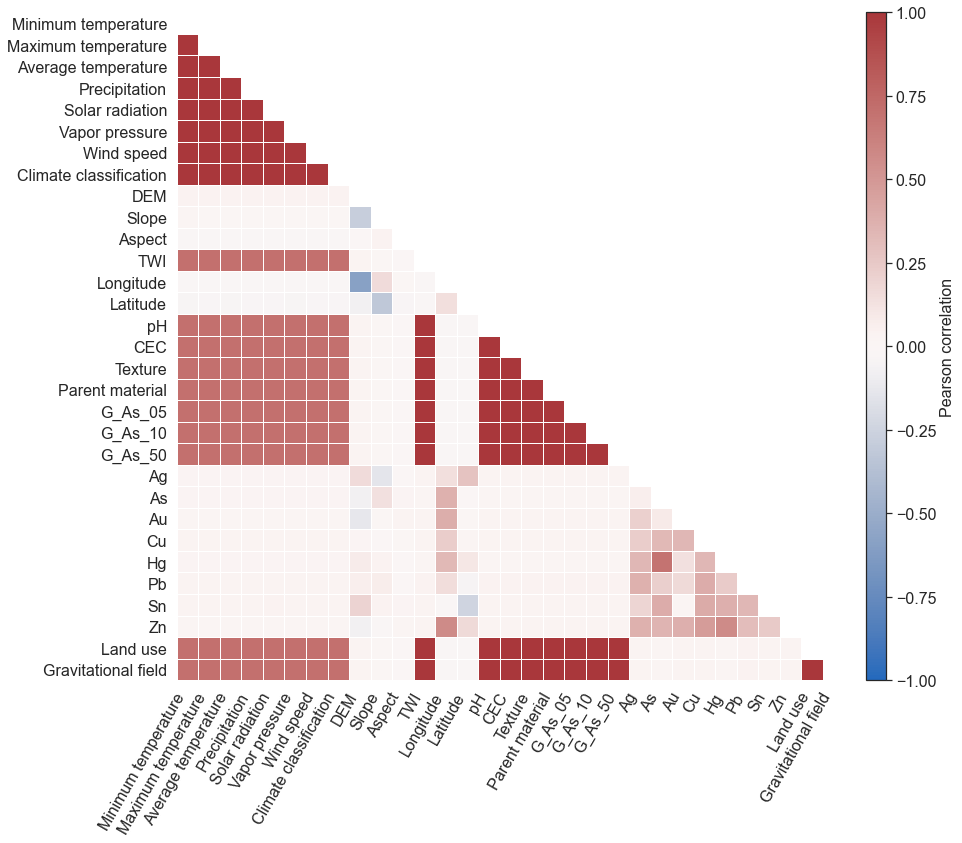

已生成最终优化版热力图，保存至：e:\NO-NC\submission\revise\correlation_analysis_beautified.jpg


In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

input_file = Path(r"e:\NO-NC\normalization\correlation_20261019.csv")
output_file = Path(r"e:\NO-NC\submission\revise\correlation_analysis_beautified.jpg")

# 1. 读取数据并转为数值型
data = pd.read_csv(input_file, encoding="utf-8-sig")
data = data.apply(pd.to_numeric, errors="coerce")

# 2. 计算 Pearson 相关系数
correlation = data.corr(method="pearson", min_periods=2)

# 3. 创建上三角掩码（只保留下三角）
mask = np.triu(np.ones_like(correlation, dtype=bool))

# 4. 设置画布风格，统一字号为 16
plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16
})

fig, ax = plt.subplots(figsize=(16, 12))

# 5. 绘制美化后的热力图（不使用内置 colorbar，以便后面做高度对齐）
heatmap = sns.heatmap(
    correlation, 
    mask=mask,                     
    ax=ax, 
    cmap="vlag",                   
    vmin=-1, vmax=1, 
    center=0, 
    square=True, 
    linewidths=0.5,                
    linecolor='white',             
    cbar=False                     # 关闭默认colorbar，手动外接对齐
)

# 6. 使用 make_axes_locatable 让右侧 Colorbar 的高度与左侧主图严格对齐
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.3)
cbar = fig.colorbar(heatmap.get_children()[0], cax=cax)

# 设置 Colorbar 标签为 R，统一字号为 16，无加粗
cbar.set_label("Pearson correlation", fontsize=16)
cbar.ax.tick_params(labelsize=16)

# 7. 坐标轴标签美化（字号 16，无加粗，右对齐防止压盖）
ax.tick_params(axis="x", labelrotation=60)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

ax.tick_params(axis="y", labelrotation=0)

# 8. 保存高清图片
fig.tight_layout()
output_file.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(
    output_file, 
    dpi=300, 
    format="jpg", 
    bbox_inches="tight", 
    pil_kwargs={"quality": 95}
)
plt.show()
plt.close(fig)

print(f"已生成最终优化版热力图，保存至：{output_file}")